In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

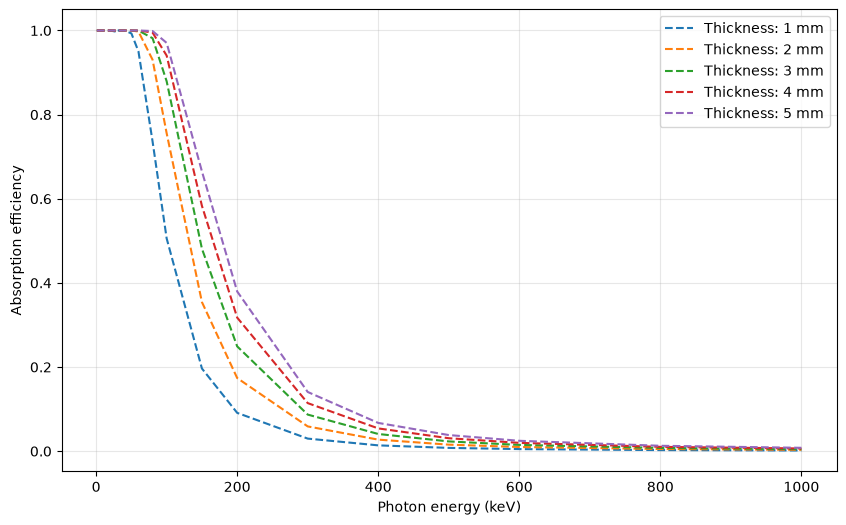

In [16]:
# for multiple thickness
rho = 5.78  # CdZnTe density (g/cm³)
thicknesses = [0.1, 0.2, 0.3, 0.4, 0.5]   # cm

df = pd.read_csv("data/photoelectric/CZT.csv", sep=r"\s+", names=["E", "pe"])  # pe = mu/rho (cm²/g)
df = df.apply(pd.to_numeric, errors="coerce").dropna()   # drops the text header rows

E = df["E"].values * 1000 # MeV -> keV

plt.figure(figsize=(10, 6))
for t in thicknesses:
    eff_pe = 1 - np.exp(-df["pe"].values * rho * t)
    plt.plot(E, eff_pe, '--', label=f'Thickness: {t*10:.0f} mm')   # plot, not semilogx

plt.xlabel("Photon energy (keV)")
plt.ylabel("Absorption efficiency")
'''plt.xlim(100, 1000)
plt.ylim(0.001, 1.05)
plt.xticks(np.arange(0, 1001, 100))
plt.yticks(np.arange(0.1, 1.01, 0.1))'''
plt.grid(alpha=0.3)
plt.legend()
plt.show()

<>:1: SyntaxWarning: invalid escape sequence '\c'
<>:1: SyntaxWarning: invalid escape sequence '\c'
C:\Users\itska\AppData\Local\Temp\ipykernel_10048\3039353053.py:1: SyntaxWarning: invalid escape sequence '\c'
  df = pd.read_csv("data\czt_tot.csv", sep=r"[,\s]+", engine="python",


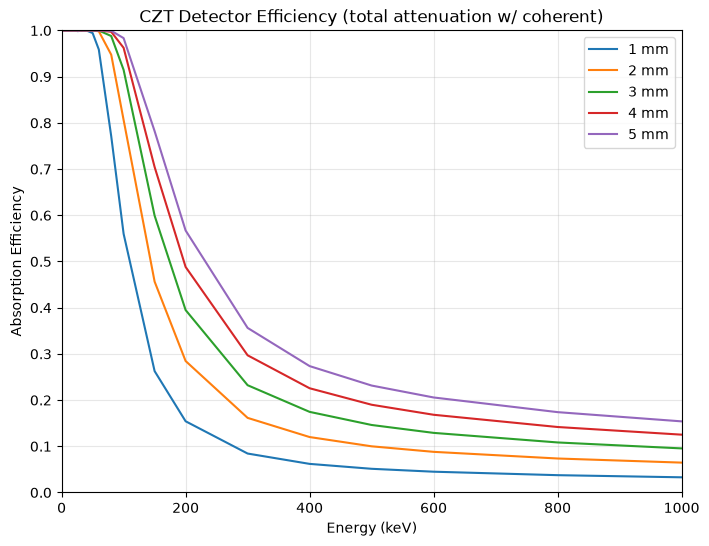

In [14]:

df = pd.read_csv("data\czt_tot.csv", sep=r"[,\s]+", engine="python",
                 comment="#", header=None, usecols=[0, 1],
                 names=["E_MeV", "mu_rho"])
df = df.apply(pd.to_numeric, errors="coerce").dropna()

E_keV = df["E_MeV"].values * 1e3          # MeV -> keV
mu_rho = df["mu_rho"].values              # cm^2/g

rho = 5.78                                # g/cm^3
mu = mu_rho * rho                         # linear attenuation, 1/cm

thicknesses_mm = [1, 2, 3, 4, 5]

fig, ax = plt.subplots(figsize=(8, 6))
for t_mm in thicknesses_mm:
    eff = 1 - np.exp(-mu * (t_mm / 10))   # mm -> cm
    ax.plot(E_keV, eff, label=f"{t_mm} mm")

ax.set(xlim=(0, 1000), ylim=(0, 1),
       xlabel="Energy (keV)", ylabel="Absorption Efficiency",
       title="CZT Detector Efficiency (total attenuation w/ coherent)")
ax.set_yticks(np.arange(0, 1.01, 0.1))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

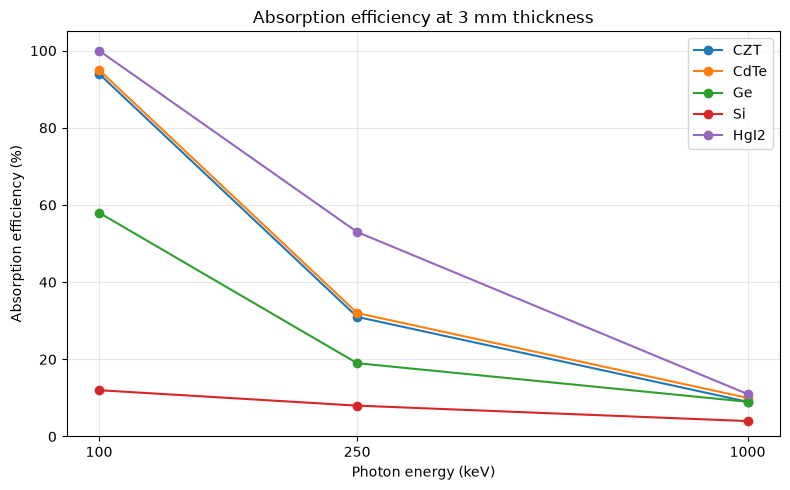

In [26]:
abs_eff = {"CZT":  [94, 31, 9],
           "CdTe": [95, 32, 10],
           "Ge":   [58, 19, 9],
           "Si":   [12, 8, 4],
           "HgI2": [100, 53, 11]}

energy = [100, 250, 1000]   # keV, at 3 mm thickness

plt.figure(figsize=(8, 5))
for material, eff in abs_eff.items():
    plt.plot(energy, eff, marker='o', ms=6, lw=1.5, label=material)

plt.xscale('log')
plt.xticks(energy, [str(e) for e in energy])   # show 100, 250, 1000 as plain labels
plt.minorticks_off()                           # removes the extra minor ticks on the log axis

plt.xlabel("Photon energy (keV)")
plt.ylabel("Absorption efficiency (%)")
plt.title("Absorption efficiency at 3 mm thickness")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

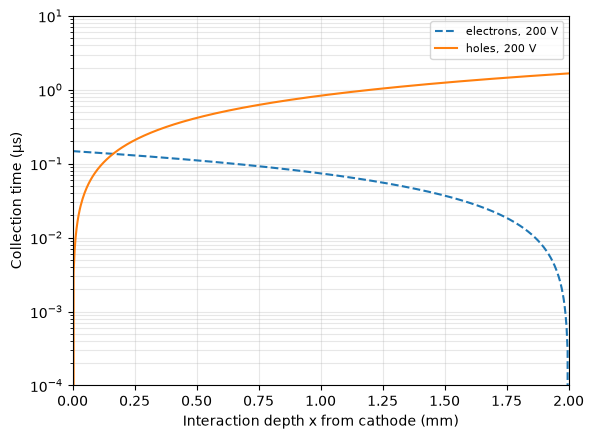

In [ ]:
d = 0.2                      
mu_e, mu_h = 1350, 120       
x = np.linspace(0, d, 500)   
x_mm = x * 10      

for V in [200]:
    E = V / d
    te = (d - x) / (mu_e * E) * 1e6   # µs
    th = x / (mu_h * E) * 1e6         # µs
    plt.plot(x_mm, te, '--', label=f"electrons, {V} V")
    plt.plot(x_mm, th, '-',  label=f"holes, {V} V")

plt.xlabel("Interaction depth x from cathode (mm)")
plt.ylabel("Collection time (µs)")
plt.yscale("log")
plt.xlim(0, 2)
plt.ylim(1e-4, 1e1)
plt.yticks([10.0**k for k in range(-4, 2)])
plt.grid(alpha=.3, which='both')
plt.legend(fontsize=8)
plt.show()